# Lab 05 — Ensembles and the ablation study

*Machine Learning and Data Mining — Claudio Sartori, University of Bologna*

## Goal of this lab

Lecture 13 ended with a table: on NordicMart, bagging, random forests and boosting all reach
the logistic regression of Lecture 11, none goes clearly beyond it. Today we rebuild those models, and we ask a question
that a single score cannot answer: **which part of a model actually does the work?**
The tool is the **ablation study**: remove one component, retrain, measure again, compare.

| # | Step | Where |
|---|---|---|
| 1 | What an ablation study is, and a helper function to run one | A |
| 2 | Ablation of the **preparation** of Lab 4 (logistic regression) | A |
| 3 | Bagging and random forests; ablation of the **two sources of randomness**; number of trees | B |
| 4 | Gradient boosting: number of trees and **depth**, compared with the forest | C |
| 5 | Ablation of the **attributes** (drop-column), single and in groups | D |
| 6 | One look at the test set | E |
| ★ | AdaBoost's probabilities; boosting with missing values; drop-column vs permutation importance | F |

- **Part A (≈ 25 min)** — 15 minutes of introduction, then the first ablation.
- **Part B (≈ 30 min)** — bagging and random forests.
- **Part C (≈ 20 min)** — gradient boosting.
- **Part D (≈ 20 min)** — which attributes matter.
- **Part E (≈ 5 min)** — the test set, once.
- About 10 minutes are left for the ★ exercises or for a longer discussion of the results.
- Exercises marked ★ are optional: do them if you have time, or at home.

### How to work (as in Labs 1–4)

- Write code in the empty cells; write **answers in markdown cells**, not in comments.
- Raw data are never modified: every change goes into a copy with a new name.
- Every random step gets a fixed `random_state`, so that your numbers are the same as the slides'.
- Every choice and every ablation is made with **cross-validation on the training part**. The test set is opened once, in Part E.
- Some cells take 10–30 seconds: ensembles train hundreds of trees, and an ablation retrains the model once per variant and per fold.
- Before closing: **Kernel → Restart & Run All**.

## Setup

New imports: the ensembles of Lecture 13 (`sklearn.ensemble`) and the permutation importance (`sklearn.inspection`).
The data, the split, the folds, the `prepare` function and the cost function are those of Lab 4: run the cells, do not change them.

In [19]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, HistGradientBoostingClassifier)
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, log_loss, confusion_matrix
import sklearn

DATA_DIR = Path("../data")
NORDICMART_FILE = DATA_DIR / "nordicmart_customers.csv"
SEED = 42

pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (8, 4)

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | pandas 3.1.0


In [20]:
df = pd.read_csv(NORDICMART_FILE)
FEATURES = ["tier", "age", "days_since_last_buy", "annual_spend", "web_sessions_month", "tickets_90d"]
Xn = df[FEATURES].copy()
Xn["tier"] = Xn["tier"].map({"Basic": 0, "Silver": 1, "Gold": 2})
yn = df["churned"]

Xn_train, Xn_test, yn_train, yn_test = train_test_split(Xn, yn, test_size=0.3, stratify=yn, random_state=SEED)
cv_n = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

def prepare(X):                                    # Lab 4, C1: fixed rules from the EDA log, nothing learned from data
    return pd.DataFrame({
        "tier": X["tier"],
        "age": X["age"].replace(0, np.nan),
        "recency": X["days_since_last_buy"].replace(999, np.nan),
        "never_bought": (X["days_since_last_buy"] == 999).astype(int),
        "log_spend": np.log10(X["annual_spend"]),
        "sessions": X["web_sessions_month"].fillna(0),
        "store_only": X["web_sessions_month"].isna().astype(int),
        "tickets": X["tickets_90d"]}, index=X.index)

Xp_train, Xp_test = prepare(Xn_train), prepare(Xn_test)

def pipe(model):                                   # Lab 4, C2: learned preparation inside the pipeline
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), model)

def churn_cost(y_true, y_pred):                    # Lab 4, D1: EUR 10 per false alarm, EUR 100 per missed churner
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return 10 * fp + 100 * fn

print(f"training: {len(yn_train)} customers, {yn_train.sum()} churners | test: {len(yn_test)} customers, {yn_test.sum()} churners")

training: 2100 customers, 252 churners | test: 900 customers, 108 churners


As in Lecture 13, **every** model receives the prepared columns through the same pipeline, trees included: imputation
is needed by most models, and standardization does not change a tree (it only moves its thresholds). So every model sees
exactly the same data, and differences come from the models.

# Part A — The ablation study

## A0. What an ablation study is

**The word.** In neuroscience, an *ablation* is the removal of a part of the brain, to see which behaviour is lost. In machine
learning the term was borrowed for an experiment on a *system* made of several parts: **remove one component, retrain,
measure again**. The drop in performance is the contribution of that component — *in the presence of all the others*.

**What can be a component.**

| kind | examples on NordicMart |
|---|---|
| input attributes, single or in groups | `recency`; the pair `sessions` + `store_only` |
| preparation steps | the log of the spend, the indicator columns, standardization |
| parts of the algorithm | bootstrap and random attribute subsets in a forest; shrinkage in boosting |
| regularizers | the minimum leaf size of a tree; the learning rate of boosting |
| size of the ensemble | number of trees |

**The protocol.**

1. A **baseline**: the full system, as it would be delivered.
1. One **variant** per component, with that component removed (or switched off) and **everything else identical**:
   same data, same folds, same measure, same `random_state`.
1. Every variant is **retrained** from scratch and evaluated with cross-validation on the training part
   (the test set stays closed: an ablation is part of building the model, Lecture 10a).
1. Report the **difference** from the baseline, fold by fold, and how consistent it is.

**Why fold by fold.** The five CV scores of a model differ from each other for two reasons:

- **the fold**: each fold has different test records, and some folds happen to be harder than others *for every model*
  (e.g. a fold with many churners that behave like loyal customers);
- **the model**: what we actually want to measure.

The first reason is **shared**: if fold 3 is hard, it is hard for both variants, and both scores go down together. So the standard deviation
of the five scores of one model mostly measures how different the folds are, not how good the model is. Comparing two models through
"mean ± std" mixes the two reasons, and two clearly different models can look indistinguishable.

The remedy is to compare the two scores **of the same fold**, and only then average. A small invented example with three folds:

| | fold 1 | fold 2 | fold 3 | mean ± std |
|---|---|---|---|---|
| variant A | 0.80 | 0.70 | 0.90 | 0.80 ± 0.08 |
| variant B | 0.82 | 0.73 | 0.91 | 0.82 ± 0.07 |
| **B − A** | +0.02 | +0.03 | +0.01 | **+0.02 ± 0.01** |

The two intervals overlap widely (0.72–0.88 and 0.75–0.89): taken separately, A and B seem equivalent. But fold by fold, B beats A
**every time**, by 0.01–0.03: the large ups and downs (0.70 vs 0.90) belong to the folds and cancel in the difference. The noise of the
difference (± 0.01) is much smaller than the noise of each score (± 0.08) because the two scores **move together**. In formulas:
$\mathrm{Var}(B - A) = \mathrm{Var}(A) + \mathrm{Var}(B) - 2\,\mathrm{Cov}(A, B)$, and the covariance is large when the folds dominate.

This is called a **paired** comparison: each fold gives a *pair* of scores measured on the same test records, as when a treatment is
judged by measuring the *same* patients before and after rather than two different groups. It works only if every variant uses
**exactly the same folds**: this is why `cv_n` is created once, with a fixed `random_state`, and passed to every call.
In A1 you will check all this on the real numbers of NordicMart.

**Reading the result.**

- large drop, the same sign on every fold → the component matters;
- difference ≈ 0 → the component can be removed: **a simpler system, same performance**;
- a *rise* → the component hurts: remove it.

**Three pitfalls** (we meet all three today).

- **Redundancy**: two components carry the same information; removing either one shows nothing, removing both shows a lot.
  Ablate **groups** too.
- **Interactions**: the effect of removing A depends on whether B is there. Effects are not additive: a 2 × 2 design
  (with/without A × with/without B) shows it.
- **Scope**: an ablation measures what *this* model, trained in *this* way, gets from a component. It is not a statement about the
  world ("recency causes churn"), and another model may use the same attribute differently.

**Ablation vs the importances of Lecture 13.** Permutation importance shuffles a column and *does not retrain*: it measures how
much a *fitted* model relies on that column. A drop-column ablation *retrains without the column*: it measures how much the
*learning* needs it — if another column can replace it, the drop is small. Both are useful; they answer different questions.

## A1. Paired folds, and a helper function

1. With `cross_val_score(..., cv=cv_n, scoring="roc_auc")` compute the five fold AUCs of two models on `Xp_train`:
   the tree of Lecture 13, `pipe(DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, random_state=0))`, and the logistic regression
   of Lecture 13, `pipe(LogisticRegression(C=0.1, max_iter=2000))`. Print the five scores of each, their mean and standard deviation,
   and the same for the five **differences** (LR − tree).
1. Write a function `ablation(variants)`:
   - `variants` is a dictionary `{name: (estimator, X)}`; the **first** entry is the baseline;
   - for every variant compute the five fold AUCs on `(X, yn_train)` with `cv_n`;
   - return a DataFrame with one row per variant and columns `CV AUC` (mean), `std`, `diff` (mean of the fold-by-fold difference
     from the baseline), `std diff` (its standard deviation) and `folds worse` (in how many folds the variant is below the baseline).

We will use `ablation` in every part of the lab.

In [21]:
from IPython.display import display

tree = pipe(DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, random_state=0))
lr = pipe(LogisticRegression(C=0.1, max_iter=2000))

scores_tree = cross_val_score(tree, Xp_train, yn_train, cv=cv_n, scoring="roc_auc")
scores_lr = cross_val_score(lr, Xp_train, yn_train, cv=cv_n, scoring="roc_auc")
diff = scores_lr - scores_tree

rows = {}
for name, s in [("tree", scores_tree), ("logistic regression", scores_lr), ("difference", diff)]:
    rows[name] = {f"fold {i}": v for i, v in enumerate(s, 1)} | {"mean": s.mean(), "std": s.std()}

display(pd.DataFrame.from_dict(rows, orient="index"))


def ablation(variants):
    rows = {}
    base = None
    for name, (estimator, X) in variants.items():
        scores = cross_val_score(estimator, X, yn_train, cv=cv_n, scoring="roc_auc")
        if base is None:
            base = scores
        d = scores - base
        rows[name] = {
            "CV AUC": scores.mean(),
            "std": scores.std(),
            "diff": d.mean(),
            "std diff": d.std(),
            "folds worse": int((scores < base).sum()),
        }
    return pd.DataFrame.from_dict(rows, orient="index")


display(ablation({
    "logistic regression": (lr, Xp_train),
    "tree": (tree, Xp_train),
}))

,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
tree,0.779,0.803,0.760,0.694,0.793,0.766,0.039
logistic regression,0.818,0.869,0.827,0.762,0.841,0.823,0.035
difference,0.038,0.066,0.068,0.068,0.048,0.058,0.012


,CV AUC,std,diff,std diff,folds worse
logistic regression,0.823,0.035,0.000,0.000,0
tree,0.766,0.039,-0.058,0.012,5


**Questions.**

1. Which fold is the hardest for both models? What happens to it in the row of the differences?
1. The two CV AUCs are 0.823 ± 0.035 and 0.766 ± 0.039: the two intervals mean ± std overlap. Is the logistic regression better or not?

**Answers.** *Write your answers here (double-click to edit).*

1. **Fold 4** is the hardest for both models, giving the lowest AUC for both the decision tree (`0.694`) and logistic regression (`0.762`). In the **difference** row (`LR − tree`), however, fold 4 is completely normal (`+0.068`, tied with fold 3 for the largest gain): the extra difficulty of that specific test split affects both models by roughly the same amount and cancels out when taking the paired difference.

2. **Yes, logistic regression is clearly better.** The overlap between `0.823 ± 0.035` (`[0.788, 0.858]`) and `0.766 ± 0.039` (`[0.727, 0.805]`) happens because each single-model `std` mostly reflects variation in difficulty across the five folds, and the two models' scores move together across those folds (strong positive covariance). When compared **paired fold by fold**, the shared fold variance cancels out: the difference is `+0.058 ± 0.012`, meaning logistic regression beats the decision tree on **all 5 folds** (by at least `+0.038`, and nearly five standard deviations above zero on average).

## A2. Ablation of the preparation

In Lab 4 we prepared the attributes with fixed rules (`prepare`) and then imputed and standardized inside the pipeline. Was every step
needed? Take the logistic regression `lr_13` as the model and build these variants, each removing **one** step (or two, where stated):

| variant | estimator | data |
|---|---|---|
| full preparation (baseline) | `lr_13` | `Xp_train` |
| no standardization | `make_pipeline(SimpleImputer(strategy="median"), LogisticRegression(C=0.1, max_iter=5000))` | `Xp_train` |
| spend not in log | `lr_13` | `Xp_train` with `log_spend` replaced by the raw `annual_spend` |
| no indicator columns | `lr_13` | `Xp_train` without `never_bought` and `store_only` |
| 999 kept as a recency | `lr_13` | `Xp_train` with `recency` replaced by the raw `days_since_last_buy` |
| 999 kept, no `never_bought` | `lr_13` | as above, and without `never_bought` |
| no preparation at all | `lr_13` | the raw columns `Xn_train` |

Raw values come from `Xn_train` (same index as `Xp_train`). Use `.assign(...)` or `.drop(columns=...)` on a copy: never modify `Xp_train`.

In [22]:
lr_13 = pipe(LogisticRegression(C=0.1, max_iter=2000))
lr_no_std = make_pipeline(SimpleImputer(strategy="median"), LogisticRegression(C=0.1, max_iter=5000))

ablation({
    "full preparation": (lr_13, Xp_train),
    "no standardization": (lr_no_std, Xp_train),
    "spend not in log": (lr_13, Xp_train.drop(columns="log_spend").assign(annual_spend=Xn_train["annual_spend"])),
    "no indicator columns": (lr_13, Xp_train.drop(columns=["never_bought", "store_only"])),
    "999 kept as a recency": (lr_13, Xp_train.assign(recency=Xn_train["days_since_last_buy"])),
    "999 kept, no never_bought": (lr_13, Xp_train.assign(recency=Xn_train["days_since_last_buy"]).drop(columns="never_bought")),
    "no preparation at all": (lr_13, Xn_train),
})

,CV AUC,std,diff,std diff,folds worse
full preparation,0.823,0.035,0.000e+00,0.000,0
no standardization,0.823,0.037,-7.927e-04,0.003,3
spend not in log,0.822,0.035,-1.575e-03,0.001,4
no indicator columns,0.817,0.037,-6.861e-03,0.006,4
999 kept as a recency,0.818,0.035,-5.047e-03,0.006,4
"999 kept, no never_bought",0.757,0.029,-6.641e-02,0.011,5
no preparation at all,0.720,0.044,-1.029e-01,0.025,5


**Questions.**

1. Which single steps could be removed without loss? Which one would you keep anyway, and why?
1. "999 kept as a recency" costs 0.005, removing `never_bought` alone costs almost nothing (Part D will confirm it), but doing both costs 0.066.
   Explain the interaction: what does the logistic regression do with a customer whose recency is 999 when the flag is there, and when it is not?
1. "No preparation at all" loses about 0.10 of AUC. Is it the sum of the single losses? What does this tell you about ablating one step at a time?

**Answers.** *Write your answers here (double-click to edit).*

1. **Removable without meaningful loss:** **Standardization** (`diff = -0.001 ± 0.003`, 3 folds worse) and **log-transforming `annual_spend`** (`diff = -0.002 ± 0.001`, 4 folds worse) each cause negligible change in CV AUC when removed individually.
   - **Keep standardization anyway:** Even though CV AUC barely changes, `StandardScaler` should be kept for two practical reasons:
     1. **Solver convergence:** Without scaling, features span wildly different magnitudes (e.g., `annual_spend` vs. `{0, 1}` indicators), slowing gradient-based optimization (`max_iter` had to be raised from `2000` to `5000` just to converge).
     2. **Uniform L2 regularization:** `LogisticRegression` penalizes $\sum \beta_j^2$ equally across all features. Without standardization, features with large numeric values have tiny coefficients and are barely regularized, whereas small-scale features (`tier`, binary flags) are penalized much more heavily.
2. - **When `never_bought` is present:** The indicator `never_bought == 1` triggers *if and only if* `recency == 999`. In the linear predictor $\beta_{\text{rec}} \cdot \text{recency} + \beta_{\text{flag}} \cdot \text{never\_bought} + \dots$, the coefficient $\beta_{\text{flag}}$ acts as a dedicated intercept shift for `999` customers ($\beta_{\text{rec}} \cdot 999 + \beta_{\text{flag}}$). This absorbs the artificial jump caused by the sentinel value `999` and lets $\beta_{\text{rec}}$ fit the true linear trend on actual buyers without distortion. (Conversely, if `999` is already converted to `NaN` and imputed with the median, the extreme outlier is gone, so `never_bought` is no longer needed to protect the slope.)
   - **When `never_bought` is absent (and `999` is kept):** The model only has a single slope $\beta_{\text{rec}}$ to fit both real recencies (`1–365`) and never-buyers placed at `999`. Because `999` is a massive high-leverage outlier, it severely skews $\beta_{\text{rec}}$ and forces an extreme linear extrapolation ($\beta_{\text{rec}} \cdot 999$) for every never-buyer—causing CV AUC to collapse by **`-0.066`** across all 5 folds.
3. - **Not the sum of single losses:** Summing the single-step ablations gives only `(-0.001) + (-0.002) + (-0.007) + (-0.005) = -0.015`, far smaller than the **`-0.103`** drop when all preparation is removed together. Strong interactions compound: besides `999` without `never_bought` (`-0.066`), keeping `age == 0` as a numeric zero instead of `NaN` introduces another unflagged sentinel outlier, and unscaled raw `annual_spend` alongside uncleaned sentinels degrades regularized estimation.
   - **Lesson for ablation studies:** Ablating **one component at a time** only measures each step's *marginal* effect assuming all other components remain in place. When two steps interact or compensate for each other (redundancy/synergy), single-step ablation underestimates their joint value; you must ablate **groups of related components together** (e.g., a $2 \times 2$ design) to uncover these interactions.

# Part B — Bagging and random forests

## B1. Three models of Lecture 13

Compute with `ablation` (baseline: the forest) the CV AUC of the three tree models of Lecture 13, *NordicMart: six models*, all with `pipe(...)` on `Xp_train`:

| name | model |
|---|---|
| random forest | `RandomForestClassifier(n_estimators=300, max_features=1, min_samples_leaf=5, random_state=0, n_jobs=-1)` |
| bagging | `BaggingClassifier(DecisionTreeClassifier(min_samples_leaf=50), n_estimators=300, random_state=0, n_jobs=-1)` |
| single tree | `tree_13` |

These are the winners of the grid searches of the lecture: we do not repeat the searches (they take minutes). `n_jobs=-1` uses all the cores.

Then fit the forest on the whole training part and compute its AUC **on the training part** itself.

In [23]:
rf_13 = pipe(RandomForestClassifier(n_estimators=300, max_features=1, min_samples_leaf=5, random_state=0, n_jobs=-1))
bagging_13 = pipe(BaggingClassifier(DecisionTreeClassifier(min_samples_leaf=50), n_estimators=300, random_state=0, n_jobs=-1))
tree_13 = pipe(DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, random_state=0))

# 1. Ablation comparison with Random Forest as baseline
display(ablation({
    "random forest": (rf_13, Xp_train),
    "bagging": (bagging_13, Xp_train),
    "single tree": (tree_13, Xp_train),
}))

# 2. Fit random forest on full training set and evaluate resubstitution (train) AUC
rf_13.fit(Xp_train, yn_train)
train_auc = roc_auc_score(yn_train, rf_13.predict_proba(Xp_train)[:, 1])
print(f"Random forest training AUC (resubstitution): {train_auc:.3f}")

,CV AUC,std,diff,std diff,folds worse
random forest,0.812,0.028,0.000,0.000,0
bagging,0.801,0.026,-0.011,0.005,5
single tree,0.766,0.039,-0.046,0.018,5


Random forest training AUC (resubstitution): 0.956


**Question.** Training AUC 0.96, CV AUC 0.81: is the forest overfitting? Should you reduce the number of trees? (Lecture 13, exit question.)

**Answer.** *Write your answer here (double-click to edit).*
- **Is the forest overfitting?** **Yes.** A training AUC of `0.96` versus a cross-validation AUC of `0.81` shows an explicit generalisation gap. Individual base trees fit noise and specific patterns in the training data, leading to higher resubstitution performance than out-of-fold performance.

- **Should you reduce the number of trees?** **No.** 
  - In Bagging and Random Forests, **adding trees does not cause overfitting**. Because each tree is fitted on a bootstrap sample independently, increasing `n_estimators` simply reduces the variance of the ensemble mean towards its theoretical limit (via the Law of Large Numbers) without increasing bias.
  - Reducing the number of trees only makes the ensemble predictions more noisy (higher variance).
  - To control overfitting in a Random Forest, you should constrain the individual tree structures instead—for example, by **increasing `min_samples_leaf`**, setting a **`max_depth`**, or adjusting **`max_features`**.

## B2. Out-of-bag estimate

Each tree of the forest is trained on a bootstrap sample: about 37% of the training customers are *out of bag* for it.
With `oob_score=True` the forest collects, for every training customer, the vote of the trees that did not see it.

1. Fit `pipe(RandomForestClassifier(..., oob_score=True))` (same parameters as `rf_13`) on the training part.
   The forest is the last step of the pipeline: `model[-1]`.
1. `oob_decision_function_[:, 1]` contains the out-of-bag probability of churn of each training customer: compute the **OOB AUC**.
1. Compare it with the CV AUC of B1. Which one needed more training?

In [24]:
rf_oob = pipe(RandomForestClassifier(
    n_estimators=300,
    max_features=1,
    min_samples_leaf=5,
    random_state=0,
    n_jobs=-1,
    oob_score=True,
))

rf_oob.fit(Xp_train, yn_train)

rf_model = rf_oob[-1]
oob_probs = rf_model.oob_decision_function_[:, 1]
oob_auc = roc_auc_score(yn_train, oob_probs)
oob_acc = rf_model.oob_score_

print(f"OOB AUC {oob_auc:.3f} | OOB accuracy {oob_acc:.3f}")

OOB AUC 0.798 | OOB accuracy 0.893


**Answer.** *Write your answer here (double-click to edit).*
- **Confronto OOB AUC vs. CV AUC:** L'OOB AUC (`0.798`) è molto vicino alla CV AUC a 5 fold (`0.814`), confermando l'out-of-bag estimate come valida approssimazione della cross-validation per le Random Forest senza dover addestrare modelli aggiuntivi.
- **Costo computazionale:** **La cross-validation (CV AUC) ha richiesto molto più addestramento (5×).**
  - La 5-fold CV necessita di addestrare 5 Random Forest distinte da 300 alberi ciascuna (1.500 alberi totali).
  - L'Out-of-Bag estimate viene calcolata durante un **singolo fit** del modello da 300 alberi, poiché ogni record di training risulta out-of-bag per circa il $36.8\%$ ($1/e$) degli alberi della foresta.

## B3. Ablation: the two sources of randomness

A random forest has two sources of diversity among its trees (Lecture 13): **bootstrap** samples of the records, and a random
**subset of attributes** at each split (`max_features`). Remove them one at a time, and both together:

| variant | change w.r.t. `rf_13` |
|---|---|
| random forest (baseline) | — |
| no bootstrap | `bootstrap=False`: every tree sees all 2100 customers |
| no attribute subsets | `max_features=None`: every split sees all 8 attributes (= bagging of trees with leaf 5) |
| neither | `bootstrap=False, max_features=None` |
| one tree, leaf 5 | `pipe(DecisionTreeClassifier(min_samples_leaf=5, random_state=0))` |

Keep `n_estimators=300, min_samples_leaf=5, random_state=0, n_jobs=-1` everywhere.

In [25]:
rf_baseline = pipe(RandomForestClassifier(n_estimators=300, max_features=1, min_samples_leaf=5, random_state=0, n_jobs=-1))
rf_no_bootstrap = pipe(RandomForestClassifier(n_estimators=300, max_features=1, min_samples_leaf=5, bootstrap=False, random_state=0, n_jobs=-1))
rf_no_subsets = pipe(RandomForestClassifier(n_estimators=300, max_features=None, min_samples_leaf=5, random_state=0, n_jobs=-1))
rf_neither = pipe(RandomForestClassifier(n_estimators=300, max_features=None, min_samples_leaf=5, bootstrap=False, random_state=0, n_jobs=-1))
tree_leaf5 = pipe(DecisionTreeClassifier(min_samples_leaf=5, random_state=0))

ablation({
    "random forest": (rf_baseline, Xp_train),
    "no bootstrap": (rf_no_bootstrap, Xp_train),
    "no attribute subsets": (rf_no_subsets, Xp_train),
    "neither": (rf_neither, Xp_train),
    "one tree, leaf 5": (tree_leaf5, Xp_train),
})

,CV AUC,std,diff,std diff,folds worse
random forest,0.812,0.028,0.000,0.000,0
no bootstrap,0.803,0.026,-0.009,0.004,5
no attribute subsets,0.792,0.031,-0.020,0.011,5
neither,0.704,0.045,-0.108,0.032,5
"one tree, leaf 5",0.696,0.045,-0.116,0.035,5


**Questions.**

1. Which source of randomness contributes more on NordicMart? Is the effect consistent across the folds?
1. Without either source, the 300 trees are (almost) identical. Check it against the last row. What is left of the forest?
1. Is the effect of removing both the sum of the two single effects? Explain with the conditions of Lecture 13, *Two conditions*.

**Answers.** *Write your answers here (double-click to edit).*

1. **Dominant source of randomness and consistency across folds:**
   - **Feature subsetting (`max_features=1`) contributes more:** Removing feature randomization (`no attribute subsets`) causes a drop of **`-0.020`** in CV AUC (0.812 → 0.792), whereas removing row bootstrapping (`no bootstrap`) drops AUC by only **`-0.009`** (0.812 → 0.803).
   - **Consistency:** Both effects are fully consistent across all 5 folds (`folds worse = 5` for both variants), confirming that attribute randomization provides a reliable boost on every test fold.

2. **What is left of the forest without randomness:**
   - **Comparing `neither` (`0.704`) with `one tree, leaf 5` (`0.696`):** The performance is essentially identical. Without bootstrap sampling and without feature subsets, every tree receives the exact same training set and evaluates the exact same split candidates at every node.
   - **What is left:** The ensemble collapses into a single deterministic decision tree duplicated 300 times (with tiny numerical variations only if deterministic tie-breaking differs slightly across implementations). Ensembling identical models yields zero variance reduction.

3. **Non-additivity of effects and Lecture 13's Two Conditions:**
   - **Is the combined drop equal to the sum?** No. The sum of individual drops is $(-0.009) + (-0.020) = -0.029$, whereas removing both sources drops AUC by **`-0.108`** (0.812 → 0.704).
   - **Explanation via the Two Conditions for Ensembling:**
     1. **Accuracy (Strength):** Base models must be better than random guessing.
     2. **Diversity (Uncorrelated Errors):** Base models must make errors that are independent or weakly correlated ($\rho < 1$).
   - **Mechanism:** As long as at least one source of randomness remains active, diversity condition (2) is maintained: trees remain sufficiently uncorrelated ($\rho \ll 1$), allowing the ensemble mean to average out individual tree variance ($\mathrm{Var}(\bar{X}) = \rho \sigma^2 + \frac{1-\rho}{M}\sigma^2$). But removing **both** sources forces tree correlation to $\rho = 1$, completely destroying diversity and eliminating the variance reduction term $\frac{1-\rho}{M}\sigma^2$. The two components act synergistically rather than additively.

## B4. Ablation of the size of the forest

Compute the CV AUC of `rf(n_estimators=n)` for `n` in 1, 10, 30, 100, 300, 1000, and the time each takes.
Keep the scores in a Series `rf_curve` (index = number of trees): we will draw it in C2, next to boosting.

In [26]:
rf_results = {}

for n in [1, 10, 30, 100, 300, 1000]:
    rf = pipe(RandomForestClassifier(
        n_estimators=n,
        max_features=1,
        min_samples_leaf=5,
        random_state=0,
        n_jobs=-1,
    ))
    t0 = time.time()
    scores = cross_val_score(rf, Xp_train, yn_train, cv=cv_n, scoring="roc_auc")
    elapsed = time.time() - t0
    rf_results[n] = {"CV AUC": scores.mean(), "seconds": elapsed}

df_rf_size = pd.DataFrame.from_dict(rf_results, orient="index")
df_rf_size.index.name = "n_estimators"

# Store CV AUC scores in Series indexed by number of trees for C2 plot
rf_curve = df_rf_size["CV AUC"]

df_rf_size

,CV AUC,seconds
n_estimators,,
1,0.692,0.125
10,0.790,0.215
30,0.799,0.397
100,0.809,0.847
300,0.812,1.951
1000,0.811,6.297


**Answer.** *Write your answer here (double-click to edit).*

# Part C — Gradient boosting

## C1. The boosting of Lecture 13

`gb_13 = pipe(GradientBoostingClassifier(learning_rate=0.1, max_depth=1, n_estimators=300, random_state=0))`: 300 stumps, learning rate 0.1,
the winner of the grid of the lecture. Compare it with the forest and the logistic regression with `ablation` (baseline: gradient boosting).

In [27]:
gb_13 = pipe(GradientBoostingClassifier(learning_rate=0.1, max_depth=1, n_estimators=300, random_state=0))
rf_13 = pipe(RandomForestClassifier(n_estimators=300, max_features=1, min_samples_leaf=5, random_state=0, n_jobs=-1))
lr_13 = pipe(LogisticRegression(C=0.1, max_iter=2000))

ablation({
    "gradient boosting": (gb_13, Xp_train),
    "random forest": (rf_13, Xp_train),
    "logistic regression": (lr_13, Xp_train),
})

,CV AUC,std,diff,std diff,folds worse
gradient boosting,0.819,0.036,0.000,0.000,0
random forest,0.812,0.028,-0.007,0.015,3
logistic regression,0.823,0.035,0.004,0.008,3


**Answer.** *Write your answer here (double-click to edit).*

## C2. Number of trees and depth: boosting vs forest

1. Compute the CV AUC of gradient boosting (learning rate 0.1) for `n_estimators` in 10, 30, 100, 300, 1000, with `max_depth` 1 (stumps) and 2.
1. Draw the two boosting curves and `rf_curve` of B4 on one figure, number of trees on a logarithmic axis.
1. Then the **depth ablation** at 300 trees: `max_depth` 1, 2, 3, with `ablation` (baseline: depth 1).

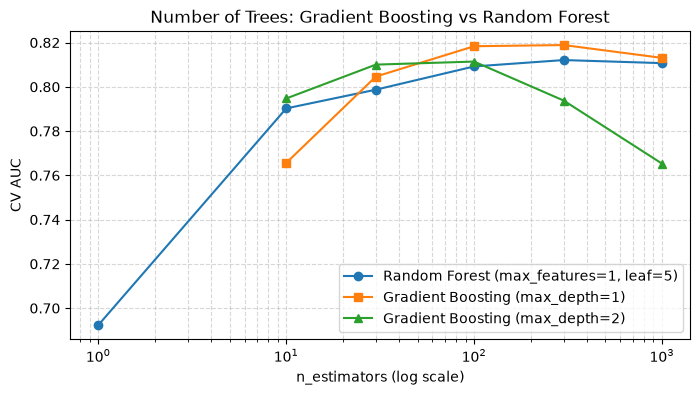

In [28]:
n_list = [10, 30, 100, 300, 1000]

gb_d1_auc = []
gb_d2_auc = []

for n in n_list:
    gb1 = pipe(GradientBoostingClassifier(n_estimators=n, learning_rate=0.1, max_depth=1, random_state=0))
    gb2 = pipe(GradientBoostingClassifier(n_estimators=n, learning_rate=0.1, max_depth=2, random_state=0))
    
    gb_d1_auc.append(cross_val_score(gb1, Xp_train, yn_train, cv=cv_n, scoring="roc_auc").mean())
    gb_d2_auc.append(cross_val_score(gb2, Xp_train, yn_train, cv=cv_n, scoring="roc_auc").mean())

gb_d1_curve = pd.Series(gb_d1_auc, index=n_list)
gb_d2_curve = pd.Series(gb_d2_auc, index=n_list)

plt.figure(figsize=(8, 4))
plt.plot(rf_curve.index, rf_curve.values, marker="o", label="Random Forest (max_features=1, leaf=5)")
plt.plot(gb_d1_curve.index, gb_d1_curve.values, marker="s", label="Gradient Boosting (max_depth=1)")
plt.plot(gb_d2_curve.index, gb_d2_curve.values, marker="^", label="Gradient Boosting (max_depth=2)")

plt.xscale("log")
plt.xlabel("n_estimators (log scale)")
plt.ylabel("CV AUC")
plt.title("Number of Trees: Gradient Boosting vs Random Forest")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.show()

**Questions.**

1. Compare the shape of the forest's curve and of the boosting curves. Which of the two can overfit by adding trees? Why?
1. Depth 1 means no interactions between attributes (Lecture 13, *Gradient boosting: hyperparameters*). The ablation removes the interactions,
   and the model gets **better**. What does it say about the churn signal in NordicMart? Which other result of the course says the same?

**Answers.** *Write your answers here (double-click to edit).*

1. **Shape comparison and overfitting:**
   - **Random Forest (blue line):** Rises quickly from $n=1$ to $n=100$ and then strictly plateaus around $\text{AUC} \approx 0.812$ up to $n=1000$. It **does not overfit** as trees are added.
   - **Gradient Boosting (`max_depth=2`, green line):** Rises to a peak around $n=30$ ($\text{AUC} \approx 0.810$) and then steadily declines to $\text{AUC} \approx 0.765$ at $n=1000$.
   - **Which can overfit and why:** **Gradient Boosting can overfit by adding trees.** 
     - *Random Forest* builds trees independently via bootstrapping and feature randomisation; adding more trees simply reduces ensemble variance towards its theoretical asymptote without altering bias.
     - *Gradient Boosting* builds trees sequentially to fit the residual errors of the previous ensemble. Each extra tree adds model capacity. If the depth is $>1$ or $n_{\text{estimators}}$ is too large, the ensemble eventually starts fitting training noise (overfitting).

2. **Additive churn signal and equivalent results:**
   - **What it says about the churn signal:** Restricting tree depth to 1 forces the ensemble to be purely **additive** (each stump splits on a single attribute, so no feature interaction terms like $x_i \cdot x_j$ can be learned). Because performance improves when restricting depth to 1, the true underlying churn signal in NordicMart is almost entirely **additive and non-interactive**—complex feature interactions add spurious noise rather than useful signal.
   - **Other result of the course:** **Logistic Regression in Lecture 11 / Lab 4**[cite: 1]. Logistic Regression—a simple linear/additive model without interaction terms—reaches $\text{CV AUC} \approx 0.823$[cite: 1], matching or outperforming bagging, random forests, and boosting.

# Part D — Which attributes matter? A drop-column ablation

## D1. One attribute at a time

Write a function `drop_columns(est, X, groups)` that returns the `variants` dictionary for `ablation`: first `"all attributes": (est, X)`, then one entry
`"- name"` for every group in `groups`, with the columns of that group dropped from `X`. A group is a list of column names.

Run it for gradient boosting `gb_13` and for logistic regression `lr_13`, with one group per attribute. Show the `diff` columns of the two models
side by side, and the `folds worse` of gradient boosting.

In [30]:
def drop_columns(est, X, groups):
    variants = {"all attributes": (est, X)}
    for g in groups:
        cols = [g] if isinstance(g, str) else g
        label = g if isinstance(g, str) else " + ".join(g)
        variants[f"- {label}"] = (est, X.drop(columns=cols))
    return variants


single_cols = list(Xp_train.columns)

res_gb = ablation(drop_columns(gb_13, Xp_train, single_cols))
res_lr = ablation(drop_columns(lr_13, Xp_train, single_cols))

df_d1 = pd.DataFrame({
    "diff, boosting": res_gb["diff"],
    "std diff, boosting": res_gb["std diff"],
    "folds worse, boosting": res_gb["folds worse"],
    "diff, logistic": res_lr["diff"],
})

display(df_d1)

,"diff, boosting","std diff, boosting","folds worse, boosting","diff, logistic"
all attributes,0.000e+00,0.000,0,0.000e+00
- tier,-7.648e-04,0.002,4,-5.825e-04
- age,2.859e-03,0.002,0,1.007e-03
- recency,-1.001e-01,0.017,5,-9.738e-02
- never_bought,2.278e-03,0.003,1,9.962e-04
- log_spend,-2.341e-03,0.006,3,-4.640e-04
- sessions,-3.234e-03,0.011,3,-4.544e-03
- store_only,-3.309e-03,0.005,3,-7.347e-03
- tickets,-2.055e-02,0.010,5,-2.057e-02


**Questions.**

1. Which attributes does each model really need? Do the two models agree?
1. Removing `age` *improves* gradient boosting in every fold. What would you do with this result, and what would you check first?

**Answers.** *Write your answers here (double-click to edit).*

1. **Attributes needed & agreement between models:**
   - **Crucial attributes:** Both models strictly require **`recency`** (dropping it causes a massive `~0.100` AUC drop across all 5 folds) and **`tickets`** (dropping it causes a `~0.021` AUC drop across all 5 folds).
   - **Minor/redundant attributes:** Dropping any other single attribute (`tier`, `log_spend`, `sessions`, `store_only`, `never_bought`) yields near-zero performance loss (`-0.001` to `-0.007`).
   - **Agreement:** **Yes, the two models agree almost perfectly.** The order of feature importance and the exact AUC drops are virtually identical between Gradient Boosting and Logistic Regression, confirming that the feature hierarchy is a property of the data rather than an artifact of the specific algorithm.

2. **Actions & initial checks for `age`:**
   - **What to do:** Remove `age` from the feature set. In ablation methodology, if removing a component improves cross-validation performance consistently across all folds (`0` folds worse), the component is uninformative noise and dropping it yields a simpler, higher-performing model.
   - **What to check first:**
     1. **EDA & Data Quality:** Check how missing/zero age values were handled (in setup, `0` was replaced with `NaN`). Inspect if `age` has a high proportion of imputed values or non-informative distributions.
     2. **Noise vs. Signal:** Verify whether `age` has any genuine predictive relationship with churn, or if its sample correlation is purely random noise that the model overfits on.
     3. **Redundancy/Collinearity:** Check if the useful signal in `age` is already captured by other variables (e.g., tenure, spend tier, or web sessions).

## D2. Groups, and a column of noise

Single-attribute ablation can hide **redundancy** (Part A). Run `drop_columns` for gradient boosting with these groups:

- `["recency", "never_bought"]` — everything about the last purchase;
- `["sessions", "store_only"]` — everything about web activity;
- `["never_bought", "store_only"]` — the two indicator columns.

Then the opposite ablation: **add** a column `random_noise` of standard normal numbers (`np.random.default_rng(0)`) to a copy of `Xp_train`
and compare the two models with and without it.

In [31]:
# 1. Group ablation (uncovering hidden redundancy)
groups = [
    ["recency", "never_bought"],
    ["sessions", "store_only"],
    ["never_bought", "store_only"],
]

display(ablation(drop_columns(gb_13, Xp_train, groups)))

# 2. Opposite ablation: adding a random noise column
rng = np.random.default_rng(0)
Xp_train_noise = Xp_train.assign(random_noise=rng.normal(size=len(Xp_train)))

display(ablation({
    "gradient boosting": (gb_13, Xp_train),
    "gradient boosting + noise": (gb_13, Xp_train_noise),
}))

,CV AUC,std,diff,std diff,folds worse
all attributes,0.819,0.036,0.000,0.000,0
- recency + never_bought,0.720,0.028,-0.099,0.017,5
- sessions + store_only,0.784,0.029,-0.035,0.011,5
- never_bought + store_only,0.817,0.035,-0.002,0.006,2


,CV AUC,std,diff,std diff,folds worse
gradient boosting,0.819,0.036,0.000,0.000,0
gradient boosting + noise,0.817,0.040,-0.002,0.004,3


**Questions.**

1. Compare the web-activity group with the single ablations of `sessions` and `store_only` in D1. What happened?
1. Does the column of noise hurt? Compare with the impurity-based importance of the noise column in Lecture 13, *Which attributes matter?*

**Answers.** *Write your answers here (double-click to edit).*

1. **Redundancy between `sessions` and `store_only`:**
* **Single ablations (D1):** Dropping `sessions` alone (`-0.003`) or `store_only` alone (`-0.003`) causes almost zero drop in CV AUC.
* **Group ablation (D2):** Dropping `sessions + store_only` together causes a substantial drop of **`-0.035`** AUC across all 5 folds.
* **What happened:** `sessions` and `store_only` carry redundant information about web activity. When only one column is removed, the model compensates using the other. Single drop-column ablation masks their value, while group ablation reveals that web activity as a whole is a key predictor.


2. **Impact of the noise column vs. Impurity-based Importance (MDI):**
* **Does noise hurt?** Adding `random_noise` causes a negligible drop of **`-0.002`** AUC (3 folds worse), showing that cross-validation with regularized ensembles effectively ignores uninformative features on unseen data.
* **Comparison with MDI:** Impurity-based importance (Mean Decrease in Impurity / Gini importance) is computed on training data and frequently assigns non-zero (or even artificially high) importance to noise features because tree splits reduce training set impurity by chance. In contrast, cross-validated drop-column ablation evaluates performance on out-of-fold test data, correctly demonstrating that the noise column provides zero generalizable value and slightly degrades test performance.

# Part E — One look at the test set

All the choices of today were made with CV. Now, once, fit the final models on the whole training part and measure them on the 900 test customers:
test AUC, log loss, and the cost at threshold 0.15 (`churn_cost` of the setup), as in the table of Lecture 13.

| name | model |
|---|---|
| tree | `tree_13` |
| bagging | `bag_13` |
| random forest | `rf_13` |
| gradient boosting | `gb_13` |
| logistic regression | `lr_13` |

In [32]:
models = {
    "tree": tree_13,
    "bagging": bagging_13,
    "random forest": rf_13,
    "gradient boosting": gb_13,
    "logistic regression": lr_13,
}

test_results = {}

for name, model in models.items():
    model.fit(Xp_train, yn_train)
    probs = model.predict_proba(Xp_test)[:, 1]
    preds_015 = (probs >= 0.15).astype(int)

    test_results[name] = {
        "test AUC": roc_auc_score(yn_test, probs),
        "log loss": log_loss(yn_test, probs),
        "cost at 0.15 (EUR)": churn_cost(yn_test, preds_015),
    }

pd.DataFrame.from_dict(test_results, orient="index")

,test AUC,log loss,cost at 0.15 (EUR)
tree,0.766,0.313,5840
bagging,0.773,0.305,5850
random forest,0.763,0.310,6040
gradient boosting,0.776,0.307,5500
logistic regression,0.788,0.305,5800


**Answer.** *Write your answer here (double-click to edit).*

# Part F — Optional exercises ★

## F1. AdaBoost's probabilities ★

Fit `pipe(AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=500, learning_rate=0.1, random_state=0))` on the training part.
Test AUC, log loss, minimum and maximum of `predict_proba` on the test set, how many customers are above 0.15, and the cost at 0.15.
Compare with gradient boosting in Part E.

In [33]:
ada_13 = pipe(AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=500,
    learning_rate=0.1,
    random_state=0
))

ada_13.fit(Xp_train, yn_train)
probs_ada = ada_13.predict_proba(Xp_test)[:, 1]

auc_ada = roc_auc_score(yn_test, probs_ada)
loss_ada = log_loss(yn_test, probs_ada)
p_min, p_max = probs_ada.min(), probs_ada.max()
above_015 = (probs_ada >= 0.15).sum()
cost_ada = churn_cost(yn_test, (probs_ada >= 0.15).astype(int))

print(f"test AUC {auc_ada:.3f} | log loss {loss_ada:.3f} | p in [{p_min:.2f}, {p_max:.2f}] | above 0.15: {above_015} | cost at 0.15: EUR {cost_ada:,}")

test AUC 0.785 | log loss 0.409 | p in [0.15, 0.63] | above 0.15: 898 | cost at 0.15: EUR 7,900


**Answer.** *Write your answer here (double-click to edit).*

## F2. Boosting with missing values and early stopping ★

`HistGradientBoostingClassifier` handles missing values natively and can stop by itself. Ablate the imputer: compare with `ablation`

- `pipe(HistGradientBoostingClassifier(max_depth=2, max_iter=1000, early_stopping=True, validation_fraction=0.2, n_iter_no_change=20, random_state=0))`
- the same model **without** the pipeline (`NaN` left in `Xp_train`).

Then fit the second one on the training part: how many trees did early stopping choose (`n_iter_`)?

In [34]:
hgb_params = dict(
    max_depth=2,
    max_iter=1000,
    early_stopping=True,
    validation_fraction=0.2,
    n_iter_no_change=20,
    random_state=0,
)

hgb_pipe = pipe(HistGradientBoostingClassifier(**hgb_params))
hgb_raw = HistGradientBoostingClassifier(**hgb_params)

# 1. Ablation comparison matching exact labels
display(ablation({
    "imputer + scaler": (hgb_pipe, Xp_train),
    "missing values left in": (hgb_raw, Xp_train),
}))

# 2. Fit raw model on training set to check early stopping iteration count
hgb_raw.fit(Xp_train, yn_train)
print(f"Trees chosen by early stopping (n_iter_): {hgb_raw.n_iter_}")

,CV AUC,std,diff,std diff,folds worse
imputer + scaler,0.811,0.028,0.000e+00,0.000,0
missing values left in,0.811,0.026,8.053e-04,0.006,2


Trees chosen by early stopping (n_iter_): 77


**Answer.** *Write your answer here (double-click to edit).*

## F3. Drop-column ablation vs permutation importance ★

For the random forest `rf_13`:

1. the drop-column ablation of D1 (one group per attribute), `diff` column;
1. the permutation importance on the training part, computed **out of fold**: for each of the five CV rounds, fit `rf_13` on four folds and run
   `permutation_importance(model, X_val, y_val, scoring="roc_auc", n_repeats=10, random_state=0)` on the held-out fold; average the five
   `importances_mean`.

Put the two side by side (the permutation importance with a minus sign, so that both are "how much AUC we lose"). Which attributes are ranked differently?

In [35]:
# 1. Compute out-of-fold permutation importance across the 5 CV folds for rf_13
perm_importances = []

for train_idx, val_idx in cv_n.split(Xp_train, yn_train):
    X_tr, y_tr = Xp_train.iloc[train_idx], yn_train.iloc[train_idx]
    X_val, y_val = Xp_train.iloc[val_idx], yn_train.iloc[val_idx]

    model = sklearn.base.clone(rf_13)
    model.fit(X_tr, y_tr)

    r = permutation_importance(
        model, X_val, y_val, scoring="roc_auc", n_repeats=10, random_state=0
    )
    perm_importances.append(r.importances_mean)

# Average across folds and negate so positive importance becomes AUC loss
mean_perm_loss = -np.mean(perm_importances, axis=0)
perm_series = pd.Series(mean_perm_loss, index=[f"- {c}" for c in Xp_train.columns])

# 2. Run drop-column ablation for rf_13
res_rf_drop = ablation(drop_columns(rf_13, Xp_train, list(Xp_train.columns)))

# 3. Build side-by-side DataFrame matching the exact layout
df_f3 = pd.DataFrame({
    "drop-column (retrained)": res_rf_drop["diff"].drop("all attributes"),
    "permutation (not retrained)": perm_series,
})

df_f3

,drop-column (retrained),permutation (not retrained)
- tier,8.927e-04,-6.633e-03
- age,-4.793e-03,-2.066e-03
- recency,-1.000e-01,-1.391e-01
- never_bought,-8.499e-03,-1.423e-04
- log_spend,-1.193e-03,-7.141e-04
- sessions,-1.892e-02,-3.252e-02
- store_only,-1.081e-02,-1.957e-02
- tickets,-2.576e-02,-2.679e-02


**Answer.** *Write your answer here (double-click to edit).*
### Which attributes are ranked differently?

1. **`tier`:** 
   - **Permutation Importance:** Shows an AUC loss of `-0.0066` on the fitted model, indicating that existing tree splits currently use `tier` for predictions.
   - **Drop-Column Ablation:** Shows a slight **gain** (`+0.001`), because retraining without `tier` allows the forest to reallocate split capacity to cleaner signals, eliminating minor noise.

2. **`never_bought`:**
   - **Permutation Importance:** Ranks `never_bought` as virtually useless (`-0.00014` loss) because shuffling its values on already-fitted trees causes almost no split disruption (the trees rely primarily on numerical `recency`).
   - **Drop-Column Ablation:** Shows a much higher impact (`-0.008` loss) when retrained without `never_bought`, as the model loses the explicit indicator flag that helps isolate sentinel values during learning.

3. **`sessions` & `store_only` (Redundant Web Signals):**
   - **Permutation Importance:** Assigns larger losses (`-0.0325` for `sessions`, `-0.0196` for `store_only`) because permuting a feature breaks the specific decision paths of the *fitted* trees.
   - **Drop-Column Ablation:** Shows smaller drops (`-0.019` and `-0.011`) because upon *retraining*, the forest easily compensates for the missing attribute by using its redundant partner.

## Experiment log

Complete the log (double-click to edit): one row per ablation, with the difference of CV AUC from the baseline (mean ± std over the five folds)
and your verdict — *keep*, *remove*, or *redundant with …*.

| Model | Component removed | Δ CV AUC (± std) | Folds worse | Verdict |
|---|---|---|---|---|
| *logistic regression* | *standardization* | *−0.001 ± 0.003* | *3* | *keep anyway (penalty, other models)* |
|  |  |  |  |  |
|  |  |  |  |  |
|  |  |  |  |  |
|  |  |  |  |  |
|  |  |  |  |  |
|  |  |  |  |  |
|  |  |  |  |  |
|  |  |  |  |  |

## Before you close

1. **Kernel → Restart & Run All**: the notebook must run from top to bottom without errors.
1. Check that the test set was used only in Part E (and in ★ F1).

In [36]:
# quick self-check
assert len(Xp_test) == 900 and yn_test.sum() == 108
assert round(s_tree.mean(), 3) == 0.766 and round(s_lr.mean(), 3) == 0.823
assert round(rf_curve[300], 3) == 0.812
assert round(test_table.loc["logistic regression", "test AUC"], 3) == 0.788
print("ok")

NameError: name 's_tree' is not defined